# Zilionis et al. 2019 — Non-Small Cell Lung Cancer (inDrop)
## 01 · Preprocessing, integration, Gate 1

Malignant cells from Zilionis 2019 NSCLC (7 patients, inDrop; a single UMIcounts leaf, mixed LUSC/LUAD histology). We load malignant cells, derive a per-sample count threshold, select overdispersed genes, integrate samples with Harmony, and judge **Gate 1** (mixed + continuous) on the regenerated embedding across an integration sweep with a per-neighbourhood metric (iLISI) — never on a scalar alone.

In [1]:
import os, sys, glob, warnings; warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>-4 (two levels below Puram)
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
ds   = name.split('-')[0] if '-' in name else name
pth  = os.path.join(*([os.pardir]*6))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata
pth_in = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + ds)
print('dataset:', name, '| category:', cat, '| raw stem:', ds)

dataset: Zilionis2019_Lung-4 | category: Lung | raw stem: Zilionis2019_Lung


### Load malignant cells
inDrop UMIcounts — the loader normalizes then log1p. `celltype` defaults to the publication's `Malignant` calls.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata = adata[adata.obs.cell_type == 'Malignant'].copy()
print('malignant raw:', adata.shape, '| X max %.2f (log1p of normalize_total)' % adata.X.max())
print('samples:', adata.obs['sample'].nunique())

malignant raw: (3995, 31797) | X max 3.11 (log1p of normalize_total)
samples: 7


### Per-sample cell-count threshold (gap-finding)
Sort per-sample malignant counts, find the largest multiplicative gap, threshold at the geometric mean across it — derived from this dataset, not inherited.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1]/vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', n.to_dict())
print(f'largest gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f}); '
      f'derived threshold (geom-mean) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells (dropped p2=75, below threshold)')

sorted per-sample counts: {'p1': 1078, 'p3': 799, 'p5': 790, 'p7': 630, 'p6': 391, 'p4': 232, 'p2': 75}
largest gap: 232 -> 75 (ratio 3.09); derived threshold (geom-mean) = 131
kept 6/7 samples -> 3920 cells (dropped p2=75, below threshold)


### Genes, overdispersion, PCA, Harmony integration sweep
iLISI on `sample` (ideal = n_samples) across a θ sweep picks integration strength; mixing plateaus and we take the strongest setting that does not collapse structure. n_pcs=20 (~50% variance; droplet-platform scale, matching the atlas precedents).

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
print('cumulative variance @ n_pcs=20 = %.3f' % adata.uns['pca']['variance_ratio'][:20].sum())

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    lab = pd.Categorical(labels).codes; out = np.empty(len(lab))
    for i in range(len(lab)):
        _, c = np.unique(lab[idx[i]], return_counts=True); p = c/c.sum(); out[i] = 1/np.sum(p**2)
    return out.mean()

s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
print(f'sample iLISI (ideal {nsamp}); pre-Harmony: %.2f' % ilisi(adata.obsm['X_pca'][:,:20], s))
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('  theta=%2d: iLISI %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:20], s)))
theta = 10
print('selected theta =', theta, '(mixing plateaus; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 248 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 248
cumulative variance @ n_pcs=20 = 0.502
sample iLISI (ideal 6); pre-Harmony: 1.38
2026-08-07 21:31:31,225 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 21:31:32,063 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 21:31:32,089 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 21:31:32,996 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 21:31:33,869 - harmonypy - INFO - Converged after 2 iterations
  theta= 2: iLISI 2.38
2026-08-07 21:31:34,128 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 21:31:34,849 - harmonypy - IN

### Remove detached islands (radius-graph, keep largest component)

In [6]:
um = adata.obsm['X_umap']
d, _ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab != main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab == main].copy()
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)
print('retained one connected component:', adata.shape[0], 'cells')

removed 0 cells in 0 detached islands
retained one connected component: 3920 cells


### Sub-region identity: is proliferation confounding the manifold?
Leiden lobes + per-lobe cycling fraction. Cycling is a scattered minority here, not a clean second lineage — confirmed orthogonal to the developmental axis in 02, so no lobe is scoped out.

In [7]:
sc.tl.leiden(adata, resolution=0.3, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('overall cycling fraction: %.3f (scattered minority; no proliferation lobe)' % adata.obs['cycling'].mean())

lobe sizes: {'3': 1279, '1': 1163, '0': 1032, '4': 371, '2': 75}
cycling fraction per lobe: {'0': 0.025, '1': 0.125, '2': 0.0, '3': 0.047, '4': 0.049}
overall cycling fraction: 0.064 (scattered minority; no proliferation lobe)


### Gate 1 — biology-before-geometry on the regenerated embedding
Judge mixing and continuity on the embedding itself: all samples (and both histologies) interspersed on one connected manifold.

6 samples share one continuous manifold; sample iLISI = 3.42 of 6.
detached islands removed above -> one connected component retained.
GATE 1: samples/histologies intermixed on one continuous manifold -> GO


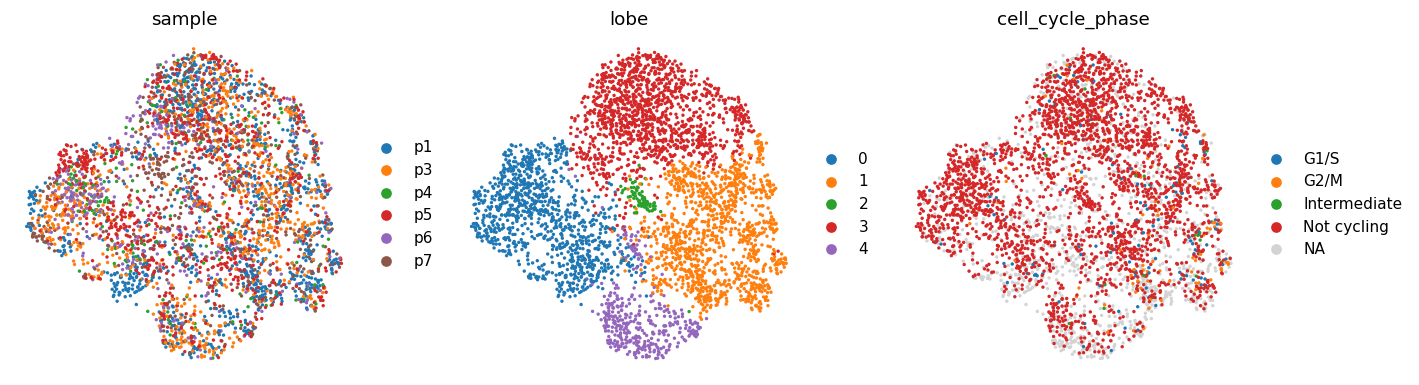

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ['sample', 'lobe', 'cell_cycle_phase']):
    sc.pl.umap(adata, color=col, size=20, frameon=False, show=False, ax=ax, title=col)
plt.tight_layout(); plt.show()
n_samp = adata.obs['sample'].nunique()
il = ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values)
print(f'{n_samp} samples share one continuous manifold; sample iLISI = {il:.2f} of {n_samp}.')
print('detached islands removed above -> one connected component retained.')
print('GATE 1: samples/histologies intermixed on one continuous manifold -> GO')

In [9]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (3920, 28282)


### Deliverable — `samples.pdf` (house layout)

saved samples.pdf | cells: 3920


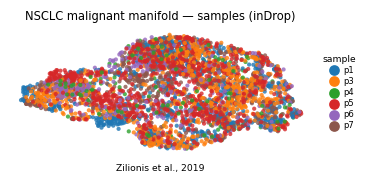

In [10]:
# House style: single sample-coloured manifold UMAP. Intermixing across the manifold is the Gate-1
# integration evidence. The linear layout used by the trajectory panels is derived in 02.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5, 1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('NSCLC malignant manifold — samples (inDrop)', size=7.5)
ax.text(.5, -.12, 'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
plt.show(); print('saved samples.pdf | cells:', plot.shape[0])